<a href="https://colab.research.google.com/github/sjadhav7279-boop/AI-ML-Assignments/blob/main/Assignment2(suvidha_dataset).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('suvidha_loan_predictions_raw.csv')
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nMissing per column:\n", df.isna().sum())
df.head()

Shape: (2400, 9)

Dtypes:
 loan_id            object
loan_amount        object
tenure_months       int64
interest_rate     float64
borrower_age       object
monthly_income     object
actual_default     object
model_flag         object
risk_score        float64
dtype: object

Missing per column:
 loan_id            0
loan_amount        0
tenure_months      0
interest_rate      0
borrower_age      38
monthly_income    36
actual_default    40
model_flag        22
risk_score         0
dtype: int64


,loan_id,loan_amount,tenure_months,interest_rate,borrower_age,monthly_income,actual_default,model_flag,risk_score
0,LN-101413,60777.81992,6,13.43,62,22029.91841,FALSE,No,0.412
1,LN-100638,258399.8923,12,11.62,28,32568.67606,No,No,0.227
2,LN-101183,114338.0322,18,14.16,42,24045.56088,0,FALSE,0.266
3,LN-101665,60919.14875,18,10.14,26,49252.29534,N,FALSE,0.211
4,LN-102068,104225.1581,12,20.41,48,20588.11472,FALSE,N,0.383


In [2]:
df['loan_amount'] = (
    df['loan_amount'].astype(str)
      .str.replace('Rs', '', regex=False)
      .str.replace(',', '', regex=False)
      .str.strip()
      .astype(float)
)
print(df['loan_amount'].describe())

count      2400.000000
mean      92862.462195
std       39819.158429
min       22062.878150
25%       63410.589692
50%       86127.625580
75%      114590.619250
max      287236.577800
Name: loan_amount, dtype: float64


In [3]:
print("actual_default raw values:\n", df['actual_default'].value_counts(dropna=False))
print("\nmodel_flag raw values:\n", df['model_flag'].value_counts(dropna=False))

truthy = {'yes', 'y', 'true', '1'}
falsy  = {'no', 'n', 'false', '0'}

def to_bool(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in truthy:
        return True
    if s in falsy:
        return False
    return np.nan   # anything unrecognized -> treated as missing, not guessed

df['actual_default'] = df['actual_default'].apply(to_bool)
df['model_flag']     = df['model_flag'].apply(to_bool)

print("\nactual_default after mapping:\n", df['actual_default'].value_counts(dropna=False))
print("\nmodel_flag after mapping:\n", df['model_flag'].value_counts(dropna=False))

actual_default raw values:
 actual_default
FALSE    869
No       448
N        431
0        413
TRUE      78
1         46
NaN       40
Y         38
Yes       37
Name: count, dtype: int64

model_flag raw values:
 model_flag
FALSE    871
No       457
N        455
0        439
TRUE      50
1         40
Y         34
Yes       32
NaN       22
Name: count, dtype: int64

actual_default after mapping:
 actual_default
False    2161
True      199
NaN        40
Name: count, dtype: int64

model_flag after mapping:
 model_flag
False    2222
True      156
NaN        22
Name: count, dtype: int64


In [4]:
before = len(df)
df = df.dropna(subset=['actual_default', 'model_flag']).reset_index(drop=True)
df['actual_default'] = df['actual_default'].astype(bool)
df['model_flag']     = df['model_flag'].astype(bool)
after = len(df)

print(f"Rows dropped: {before - after}")
print(f"Rows remaining: {after}")

Rows dropped: 61
Rows remaining: 2339


In [5]:
df['monthly_income_clean'] = pd.to_numeric(df['monthly_income'], errors='coerce')  # 'not disclosed' -> NaN
print("Rows where raw value was exactly -1:", (df['monthly_income_clean'] == -1).sum())

df.loc[df['monthly_income_clean'] == -1, 'monthly_income_clean'] = np.nan
print("Missing monthly_income after treating -1 as missing:", df['monthly_income_clean'].isna().sum(), "/", len(df))

Rows where raw value was exactly -1: 28
Missing monthly_income after treating -1 as missing: 91 / 2339


In [6]:
TP = ((df['actual_default'] == True)  & (df['model_flag'] == True)).sum()
FP = ((df['actual_default'] == False) & (df['model_flag'] == True)).sum()
TN = ((df['actual_default'] == False) & (df['model_flag'] == False)).sum()
FN = ((df['actual_default'] == True)  & (df['model_flag'] == False)).sum()

cm = pd.DataFrame([[TN, FP], [FN, TP]],
                   index=['Actual: No default', 'Actual: Default'],
                   columns=['Predicted: No default', 'Predicted: Default'])
print(cm)
print(f"\nTP={TP}  FP={FP}  TN={TN}  FN={FN}")

                    Predicted: No default  Predicted: Default
Actual: No default                   2122                  20
Actual: Default                        64                 133

TP=133  FP=20  TN=2122  FN=64


In [7]:
accuracy = (TP + TN) / (TP + FP + TN + FN)
base_rate = df['actual_default'].mean()
print(f"Accuracy: {accuracy:.4f}")
print(f"Base default rate: {base_rate:.4f}")

Accuracy: 0.9641
Base default rate: 0.0842


In [8]:
precision = TP / (TP + FP)
print(f"Precision: {precision:.4f}")

Precision: 0.8693


In [9]:
recall = TP / (TP + FN)
print(f"Recall: {recall:.4f}")

Recall: 0.6751


In [10]:
specificity = TN / (TN + FP)
print(f"Specificity: {specificity:.4f}")

Specificity: 0.9907


In [11]:
f1 = 2 * precision * recall / (precision + recall)
print(f"F1-score: {f1:.4f}")

F1-score: 0.7600


In [12]:
threshold = 0.3
pred_03 = df['risk_score'] >= threshold

TP3 = ((df['actual_default'] == True)  & pred_03).sum()
FP3 = ((df['actual_default'] == False) & pred_03).sum()
TN3 = ((df['actual_default'] == False) & ~pred_03).sum()
FN3 = ((df['actual_default'] == True)  & ~pred_03).sum()

precision_03 = TP3 / (TP3 + FP3)
recall_03    = TP3 / (TP3 + FN3)

print(f"At threshold 0.3:  TP={TP3}  FP={FP3}  TN={TN3}  FN={FN3}")
print(f"Precision: {precision_03:.4f}  (was {precision:.4f} at the model's default cutoff)")
print(f"Recall:    {recall_03:.4f}  (was {recall:.4f} at the model's default cutoff)")

At threshold 0.3:  TP=197  FP=1478  TN=664  FN=0
Precision: 0.1176  (was 0.8693 at the model's default cutoff)
Recall:    1.0000  (was 0.6751 at the model's default cutoff)


   threshold  precision    recall
0        0.1   0.085355  1.000000
1        0.2   0.091884  1.000000
2        0.3   0.117612  1.000000
3        0.4   0.203191  0.969543
4        0.5   0.440964  0.928934
5        0.6   0.826347  0.700508
6        0.7   0.974359  0.385787
7        0.8   1.000000  0.131980
8        0.9   1.000000  0.015228


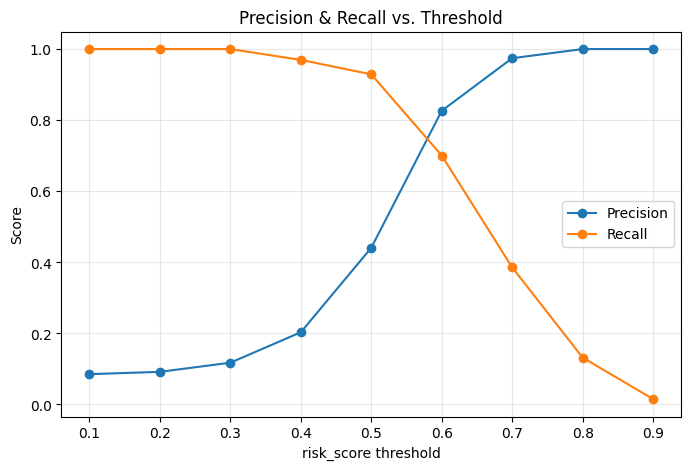

In [13]:
thresholds = np.round(np.arange(0.1, 1.0, 0.1), 1)
precisions, recalls = [], []

for t in thresholds:
    pred = df['risk_score'] >= t
    tp = ((df['actual_default'] == True) & pred).sum()
    fp = ((df['actual_default'] == False) & pred).sum()
    fn = ((df['actual_default'] == True) & ~pred).sum()
    precisions.append(tp / (tp + fp) if (tp + fp) > 0 else np.nan)
    recalls.append(tp / (tp + fn) if (tp + fn) > 0 else np.nan)

curve = pd.DataFrame({'threshold': thresholds, 'precision': precisions, 'recall': recalls})
print(curve)

plt.figure(figsize=(8,5))
plt.plot(curve['threshold'], curve['precision'], marker='o', label='Precision')
plt.plot(curve['threshold'], curve['recall'], marker='o', label='Recall')
plt.xlabel('risk_score threshold')
plt.ylabel('Score')
plt.title('Precision & Recall vs. Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:
grp_default    = df.loc[df['actual_default'] == True,  'loan_amount']
grp_no_default = df.loc[df['actual_default'] == False, 'loan_amount']

print(f"Defaulted    : mean = {grp_default.mean():.2f}   n = {len(grp_default)}")
print(f"Not defaulted: mean = {grp_no_default.mean():.2f}   n = {len(grp_no_default)}")
print(f"Difference   : {grp_default.mean() - grp_no_default.mean():.2f}")

Defaulted    : mean = 96899.91   n = 197
Not defaulted: mean = 92408.81   n = 2142
Difference   : 4491.10


In [15]:
t_stat, p_value = stats.ttest_ind(grp_default, grp_no_default, equal_var=False)
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {p_value:.4f}")

t-statistic: 1.3588
p-value:     0.1756


In [16]:
grp_default_ir    = df.loc[df['actual_default'] == True,  'interest_rate']
grp_no_default_ir = df.loc[df['actual_default'] == False, 'interest_rate']

print(f"Defaulted    : mean = {grp_default_ir.mean():.3f}   n = {len(grp_default_ir)}")
print(f"Not defaulted: mean = {grp_no_default_ir.mean():.3f}   n = {len(grp_no_default_ir)}")

t_stat_ir, p_value_ir = stats.ttest_ind(grp_default_ir, grp_no_default_ir, equal_var=False)
print(f"\nt-statistic: {t_stat_ir:.4f}")
print(f"p-value:     {p_value_ir:.4f}")

Defaulted    : mean = 14.802   n = 197
Not defaulted: mean = 14.462   n = 2142

t-statistic: 1.5778
p-value:     0.1160


In [17]:
summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Value':  [accuracy, precision, recall, f1]
})
summary['Value'] = summary['Value'].round(4)
summary

,Metric,Value
0,Accuracy,0.9641
1,Precision,0.8693
2,Recall,0.6751
3,F1-score,0.7600
